# General relativity 5: Orbits and the precession of Mercury

*Learning path: general relativity, part 5 of 9.* [Index](README.md) · Previous: [Black holes](04-black-holes.ipynb) · Next: [Light](06-light.ipynb)

Planets follow geodesics of the Schwarzschild spacetime. Far from the Sun these are almost Newton's ellipses, but not
quite, and the difference was the first triumph of general relativity. You will learn

* how the effective potential describes orbits, in Newton's theory and in Einstein's,
* why there is an innermost stable circular orbit around a black hole,
* why orbits in general relativity do not close but trace rosettes,
* how to compute the 43 arcseconds per century of Mercury's perihelion precession.

## 1. The effective potential

For a particle with angular momentum $L$ per unit mass, the Schwarzschild geodesic equations reduce to one equation
for the radius, like a ball rolling in a potential:

$$\left(\frac{dr}{d\tau}\right)^2 + V(r) = E^2, \qquad V(r) = \left(1 - \frac{r_s}{r}\right)\left(1 + \frac{L^2}{r^2}\right)$$

Multiplying out, $V = 1 - \dfrac{r_s}{r} + \dfrac{L^2}{r^2} - \dfrac{r_s L^2}{r^3}$. The first three terms are Newton's:
gravity pulling in, and the centrifugal barrier $L^2/r^2$ pushing out. The last term is new, and it wins at small $r$.
Here $V$ is for $r_s = 1$ and several values of $L$:

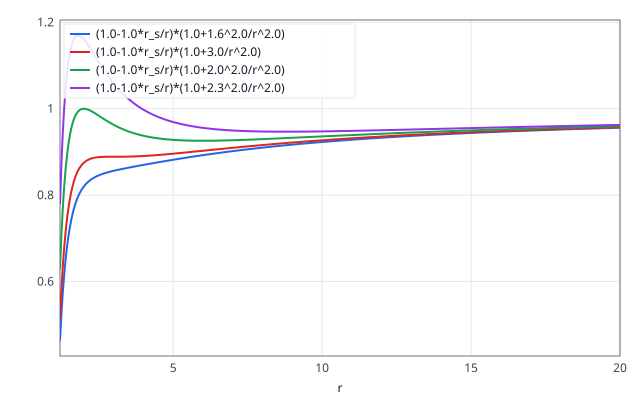

In [1]:
r_s = 1;
v1 = plot((1-r_s/r)*(1+1.6^2/r^2), r, 1.2, 20);
v2 = plot((1-r_s/r)*(1+3/r^2), r, 1.2, 20);
v3 = plot((1-r_s/r)*(1+2^2/r^2), r, 1.2, 20);
v4 = plot((1-r_s/r)*(1+2.3^2/r^2), r, 1.2, 20);
show(v1, v2, v3, v4)

A circular orbit sits at a minimum of $V$. For large $L$ (the top curves) there is a minimum, and a maximum closer in.
As $L$ decreases they merge, at $L^2 = 3r_s^2$, at radius $r = 3r_s$: the **innermost stable circular orbit** (ISCO) [7].
Closer in, nothing can orbit stably; matter spirals into the black hole. The inner edge of the glowing accretion disc
around a black hole sits at the ISCO. In Newton's theory, by contrast, the barrier $L^2/r^2$ always wins at small $r$:

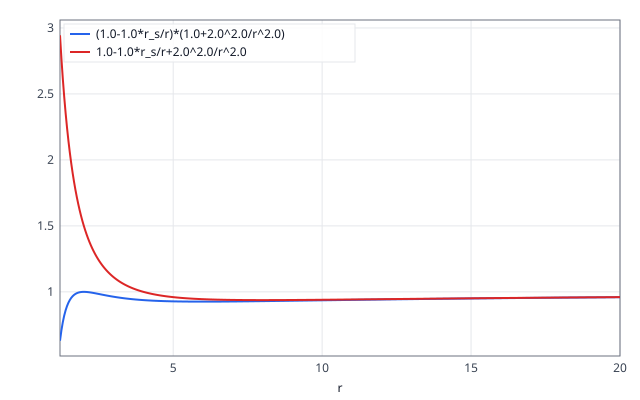

In [2]:
show(plot((1-r_s/r)*(1+2^2/r^2), r, 1.2, 20), plot(1 - r_s/r + 2^2/r^2, r, 1.2, 20))

## 2. Rosettes

With $u = 1/r$ as a function of the angle $\phi$, the orbit equations are (with $c = 1$, so $GM = r_s/2$):

* Newton: $\;u'' + u = \dfrac{GM}{h^2}$, whose solutions are ellipses that close on themselves;
* Einstein: $\;u'' + u = \dfrac{GM}{h^2} + 3GM\,u^2$.

For Mercury the extra term is tiny. To *see* it, take an orbit close to a black hole: perihelion at $20\,r_s$, aphelion
at $60\,r_s$. `odeplot` solves both equations and draws $x = \cos\phi/u$, $y = \sin\phi/u$:

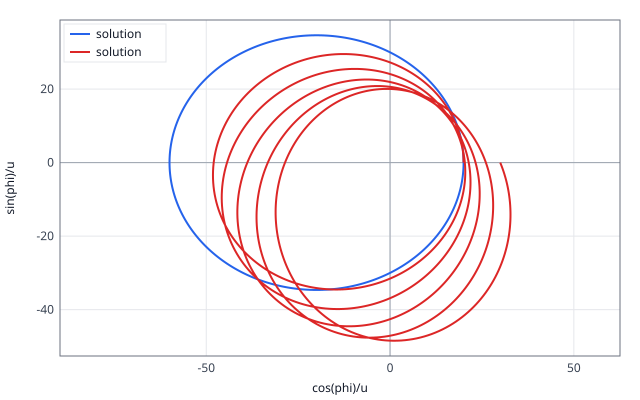

In [3]:
r_s = 1;
h = sqrt(15);
rp = 20;
newton = odeplot([w, r_s/(2*h^2)-u], [u w], phi, [1/rp 0], 0, 10*pi, [cos(phi)/u sin(phi)/u]);
einstein = odeplot([w, r_s/(2*h^2)+1.5*r_s*u^2-u], [u w], phi, [1/rp 0], 0, 10*pi, [cos(phi)/u sin(phi)/u]);
show(newton, einstein)

The Newtonian ellipse retraces itself; the relativistic orbit turns a little further each time. The predicted shift per
orbit is $\Delta\phi = 6\pi GM/\big(c^2 a(1 - e^2)\big) = 3\pi r_s/p$, with $p = h^2/GM$ the semi-latus rectum, here
$30\,r_s$. In degrees:

In [4]:
p = 2*h^2/r_s
eval(3*pi*r_s/p*180/pi)

30.0
18.0

## 3. Straight from the metric

The orbit equation above came from the geodesic equations, but we can also integrate the full four-dimensional
geodesic equations directly. The planet starts at perihelion with $\dot\phi = L/r^2$ and $\dot t$ fixed so that
$g_{ab}\dot x^a\dot x^b = -1$. This time we draw the orbit on Flamm's paraboloid from part 4, the shape of space around
the mass:

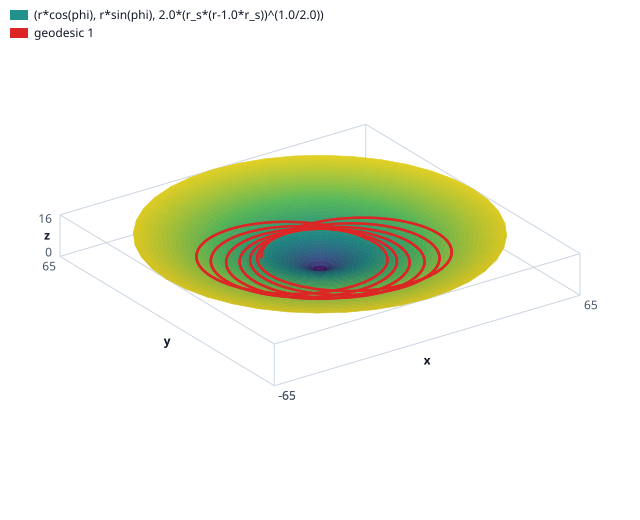

In [5]:
S = metric.generate(schwarzschild);
L = h;
ut = sqrt((1+L^2/rp^2)/(1-r_s/rp));
orbit = geodesic(S, [0 rp pi/2 0], [ut 0 0 L/rp^2], 11000, [r*cos(phi) r*sin(phi) 2*sqrt(r_s*(r-r_s))], 20000);
well = surface(r*cos(phi), r*sin(phi), 2*sqrt(r_s*(r-r_s)), r, 1, 65, phi, 0, 2*pi);
show(well, orbit)

The same rosette, now as a path on the curved surface.

## 4. Mercury

Now the real numbers, in SI units: the Sun's $GM$, the speed of light, and Mercury's semi-major axis, eccentricity and
orbital period in days [5].

In [6]:
clear
GM = 1.32712440018e20;
c = 299792458;
A = 5.7909e10;
ecc = 0.2056;
T = 87.969;
dphi = eval(6*pi*GM/(c^2*A*(1-ecc^2)))

5.018602644417365E-7

That is the shift per orbit, in radians. Mercury goes around $36525/T$ times per century. In arcseconds per century:

In [7]:
eval(dphi*(36525/T)*(180/pi)*3600)

42.98020808869248

**43 arcseconds per century.** Astronomers measure Mercury's perihelion advancing by about 574″ per century relative
to the stars, of which about 531″ is caused by the pull of the other planets [1]. Le Verrier found the anomaly in 1859 and
suggested an unseen planet inside Mercury's orbit, later called Vulcan [2]; the residual stayed a mystery for over half a
century. In November 1915 Einstein computed this number from his new theory [3], and
wrote to Paul Ehrenfest in January 1916 that "for a few days, I was beside myself with joyous excitement" [4].

> **A note on "retrograde".** Mercury's *retrograde* motion, when it seems to move backwards across the sky for a few
> weeks, is a different thing: a line-of-sight effect as Earth overtakes it or it overtakes Earth. Copernicus and
> Newton explain that fully.

The same effect is much larger in binary pulsars: for the Hulse–Taylor pulsar it is 4.2° per *year* [6].

## Summary

* Orbits follow from the effective potential $V = (1 - r_s/r)(1 + L^2/r^2)$; the extra $-r_sL^2/r^3$ is relativistic.
* No stable circular orbits exist inside $3r_s$ (the ISCO).
* Relativistic orbits precess by $6\pi GM/(c^2a(1-e^2))$ per orbit: 43″ per century for Mercury.

**Try it:** set `rp = 10` (perihelion at $10r_s$) in section 2. How fast does the rosette turn now?

Next: [Light](06-light.ipynb): bending, the photon sphere, and the shadow of a black hole.

## Sources

Numbers in square brackets in the text refer to this list.

1. G. M. Clemence, "The relativity effect in planetary motions", *Reviews of Modern Physics* **19**, 361–364 (1947): observed 574.10″ ± 0.65″ per century relative to the stars, planetary perturbations 531.54″, residual 42.56″ ± 0.94″. [doi:10.1103/RevModPhys.19.361](https://doi.org/10.1103/RevModPhys.19.361)
2. U. Le Verrier, "Lettre de M. Le Verrier à M. Faye sur la théorie de Mercure et sur le mouvement du périhélie de cette planète", *Comptes rendus de l'Académie des sciences* **49**, 379–383 (1859).
3. A. Einstein, "Erklärung der Perihelbewegung des Merkur aus der allgemeinen Relativitätstheorie", *Sitzungsberichte der Preußischen Akademie der Wissenschaften*, 831–839 (18 November 1915).
4. Einstein to Paul Ehrenfest, 17 January 1916, *The Collected Papers of Albert Einstein*, Vol. 8, Doc. 182, Princeton University Press (1998); quoted in A. Pais, *'Subtle is the Lord...'*, Oxford University Press (1982), p. 253.
5. NASA Goddard, *Mercury Fact Sheet*, [nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html](https://nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html); solar GM from IAU 2015 Resolution B3, [arXiv:1510.07674](https://arxiv.org/abs/1510.07674).
6. J. M. Weisberg and Y. Huang, "Relativistic measurements from timing the binary pulsar PSR B1913+16", *Astrophysical Journal* **829**, 55 (2016): 4.226585° per year. [doi:10.3847/0004-637X/829/1/55](https://doi.org/10.3847/0004-637X/829/1/55)
7. C. W. Misner, K. S. Thorne and J. A. Wheeler, *Gravitation*, W. H. Freeman (1973). Chapter 25 (orbits in the Schwarzschild geometry).